In [3]:
!pip install -q scikit-learn matplotlib seaborn pandas tqdm

In [4]:
import os
import json
import time
import random
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torchvision

from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import Food101
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tqdm.auto import tqdm

In [14]:
SEED = 42
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"

BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 1e-3
MAX_TRAIN_PER_CLASS = 500
MAX_VAL_PER_CLASS = 100
MAX_TEST_PER_CLASS = 250
NUM_WORKERS =0



In [6]:


SELECTED_CLASSES = [
    "hamburger",
    "pancakes",
    "pizza",
    "steak",
    "sushi",
]


DATA_DIR = "/content/data"
OUTPUT_DIR = Path("/content/foodvision_efficientnet")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


train_raw = Food101(
    root=DATA_DIR,
    split="train",
    download=True
)

test_raw =Food101(
    root=DATA_DIR,
    split="test",
    download=True
)

100%|██████████| 5.00G/5.00G [07:12<00:00, 11.6MB/s]


In [7]:
class Food101MappedDataset(Dataset):
    def __init__(
        self,
        base_dataset,
        indices,
        label_mapping,
        transform=None
    ):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.label_mapping = label_mapping
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        original_index = self.indices[index]

        image, original_label = self.base_dataset[original_index]
        new_label = self.label_mapping[original_label]

        if self.transform:
            image = self.transform(image)

        return image, new_label


class_names = SELECTED_CLASSES

class_to_new_idx = {
    name: i for i, name in enumerate(class_names)
}

label_mapping = {
    train_raw.class_to_idx[name]: class_to_new_idx[name]
    for name in class_names
}

train_labels = train_raw._labels
test_labels = test_raw._labels

rng = random.Random(SEED)

train_indices = []
val_indices = []
test_indices = []

for class_name in class_names:
    old_label = train_raw.class_to_idx[class_name]

    class_train = [
        i for i, label in enumerate(train_labels)
        if label == old_label
    ]

    class_test = [
        i for i, label in enumerate(test_labels)
        if label == old_label
    ]

    rng.shuffle(class_train)
    rng.shuffle(class_test)

    n_train = min(
        MAX_TRAIN_PER_CLASS,
        len(class_train) - MAX_VAL_PER_CLASS
    )

    n_val = min(
        MAX_VAL_PER_CLASS,
        len(class_train) - n_train
    )

    n_test = min(
        MAX_TEST_PER_CLASS,
        len(class_test)
    )

    train_indices.extend(class_train[:n_train])

    val_indices.extend(
        class_train[n_train:n_train + n_val]
    )

    test_indices.extend(class_test[:n_test])

rng.shuffle(train_indices)
rng.shuffle(val_indices)
rng.shuffle(test_indices)

print("Treino:", len(train_indices))
print("Validação:", len(val_indices))
print("Teste:", len(test_indices))

Treino: 2500
Validação: 500
Teste: 1250


In [8]:
weights = EfficientNet_B0_Weights.DEFAULT

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)



train_transformer = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)

])


eval_transformer = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean,std)


])





In [9]:
train_dataset = Food101MappedDataset(
    train_raw, train_indices, label_mapping, train_transformer
)

val_dataset = Food101MappedDataset(
    train_raw, val_indices, label_mapping, eval_transformer
)


test_dataset = Food101MappedDataset(
    test_raw, test_indices, label_mapping, eval_transformer
)



train_dataloader = DataLoader(
    train_dataset,
    batch_size = BATCH_SIZE,
    shuffle=True,
    num_workers = NUM_WORKERS
)


val_dataloader = DataLoader(
    val_dataset,
    batch_size = BATCH_SIZE,
    shuffle=False,
    num_workers = NUM_WORKERS
)


test_dataloader = DataLoader(
    test_dataset,
    batch_size = BATCH_SIZE,
    shuffle=False,
    num_workers = NUM_WORKERS
)

In [10]:
print("Batches de treino:", len(train_dataloader))
print("Batches de validação:", len(val_dataloader))
print("Batches de teste:", len(test_dataloader))

Batches de treino: 79
Batches de validação: 16
Batches de teste: 40


In [16]:
model = efficientnet_b0(weights=weights)

for param in model.features.parameters():
  param.requires_grad = False

print(model.classifier)
in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    len(class_names)
)


model = model.to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.1,
    patience=2,
    min_lr=1e-7
)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)


In [12]:
def trainModel (model, dataloader, loss_fn, optimizer=None):

  training = optimizer is not None

  if training:
    model.train()
  else:
    model.eval()

  total_loss = 0.0
  all_predictions = []
  all_labels = []

  context = (
        torch.enable_grad()
        if training
        else torch.inference_mode()
    )

  with context:
    for images, labels in tqdm(dataloader, leave=False):
      images = images.to(device)
      labels = labels.to(device)

      if training:
        optimizer.zero_grad(set_to_none=True)

      logits = model(images)
      loss = loss_fn(logits, labels)

      if training:
        loss.backward()
        optimizer.step()

      total_loss += loss.item() * images.size(0)
      predictions = logits.argmax(dim=1)

      all_predictions.extend(
                predictions.cpu().numpy().tolist()
            )

      all_labels.extend(
                labels.cpu().numpy().tolist()
            )

  average_loss = total_loss / len(dataloader.dataset)

  accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

  return (
        average_loss,
        accuracy,
        all_labels,
        all_predictions
    )





In [17]:
history = []

best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
best_epoch = 0

start_time = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.perf_counter()

    train_loss, train_acc, _, _ = trainModel(
        model,
        train_dataloader,
        loss_fn,
        optimizer
    )

    val_loss, val_acc, _, _ = trainModel(
        model,
        val_dataloader,
        loss_fn
    )

    scheduler.step(val_loss)

    epoch_time = time.perf_counter() - epoch_start

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "epoch_seconds": epoch_time
    })

    print(
        f"Época {epoch}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.4f} | "
        f"Tempo: {epoch_time:.1f}s"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch

training_seconds = time.perf_counter() - start_time

model.load_state_dict(best_state)

history_df = pd.DataFrame(history)

history_df.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

print(f"Tempo total: {training_seconds / 60:.2f} minutos")
print("Melhor época:", best_epoch)

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

Época 1/10 | Train loss: 1.1634 | Train acc: 0.6164 | Val loss: 0.7576 | Val acc: 0.8060 | Tempo: 20.3s


  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

...

Época 9/10 | Train loss: 0.5755 | Train acc: 0.7936 | Val loss: 0.4334 | Val acc: 0.8480 | Tempo: 20.8s


  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cbe78353c40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cbe78353c40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Época 10/10 | Train loss: 0.5640 | Train acc: 0.8060 | Val loss: 0.4178 | Val acc: 0.8560 | Tempo: 22.1s
Tempo total: 5.16 minutos
Melhor época: 10


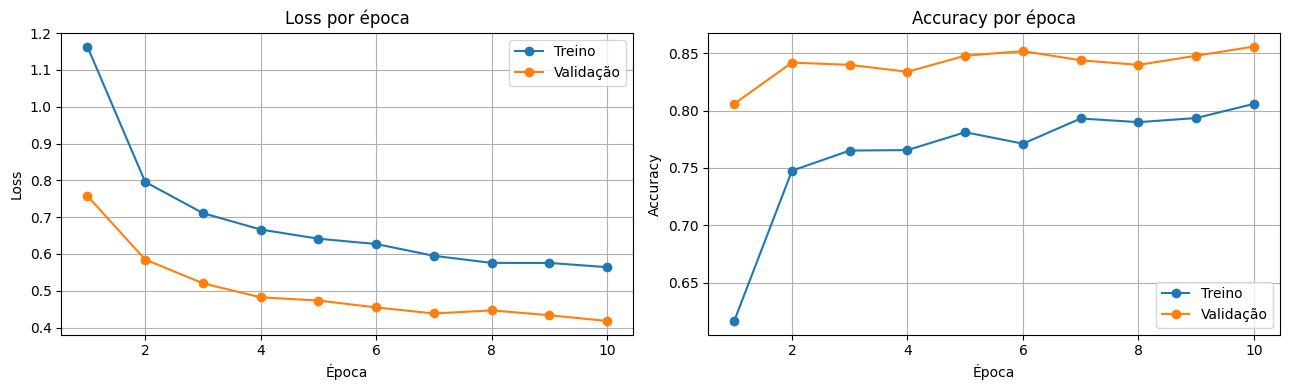

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Treino"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validação"
)

axes[0].set_title("Loss por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Treino"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validação"
)

axes[1].set_title("Accuracy por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "training_curves.png",
    dpi=160
)
plt.show()

In [19]:
test_loss, test_acc, y_true, y_pred = trainModel(
    model,
    test_dataloader,
    loss_fn
)

metrics = {
    "model": "EfficientNet-B0",
    "num_classes": len(class_names),
    "best_epoch": best_epoch,
    "training_seconds": training_seconds,
    "test_loss": test_loss,
    "accuracy": accuracy_score(y_true, y_pred),
    "precision_macro": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "recall_macro": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "f1_macro": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
}

print(json.dumps(metrics, indent=2))

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

with open(
    OUTPUT_DIR / "metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

pd.DataFrame([metrics]).to_csv(
    OUTPUT_DIR / "metrics.csv",
    index=False
)

  0%|          | 0/40 [00:00<?, ?it/s]

{
  "model": "EfficientNet-B0",
  "num_classes": 5,
  "best_epoch": 10,
  "training_seconds": 309.6862023509998,
  "test_loss": 0.30362300214767457,
  "accuracy": 0.904,
  "precision_macro": 0.9043851337162121,
  "recall_macro": 0.9039999999999999,
  "f1_macro": 0.9035797571959308
}
              precision    recall  f1-score   support

   hamburger       0.92      0.83      0.87       250
    pancakes       0.91      0.93      0.92       250
       pizza       0.95      0.98      0.96       250
       steak       0.85      0.89      0.87       250
       sushi       0.90      0.90      0.90       250

    accuracy                           0.90      1250
   macro avg       0.90      0.90      0.90      1250
weighted avg       0.90      0.90      0.90      1250



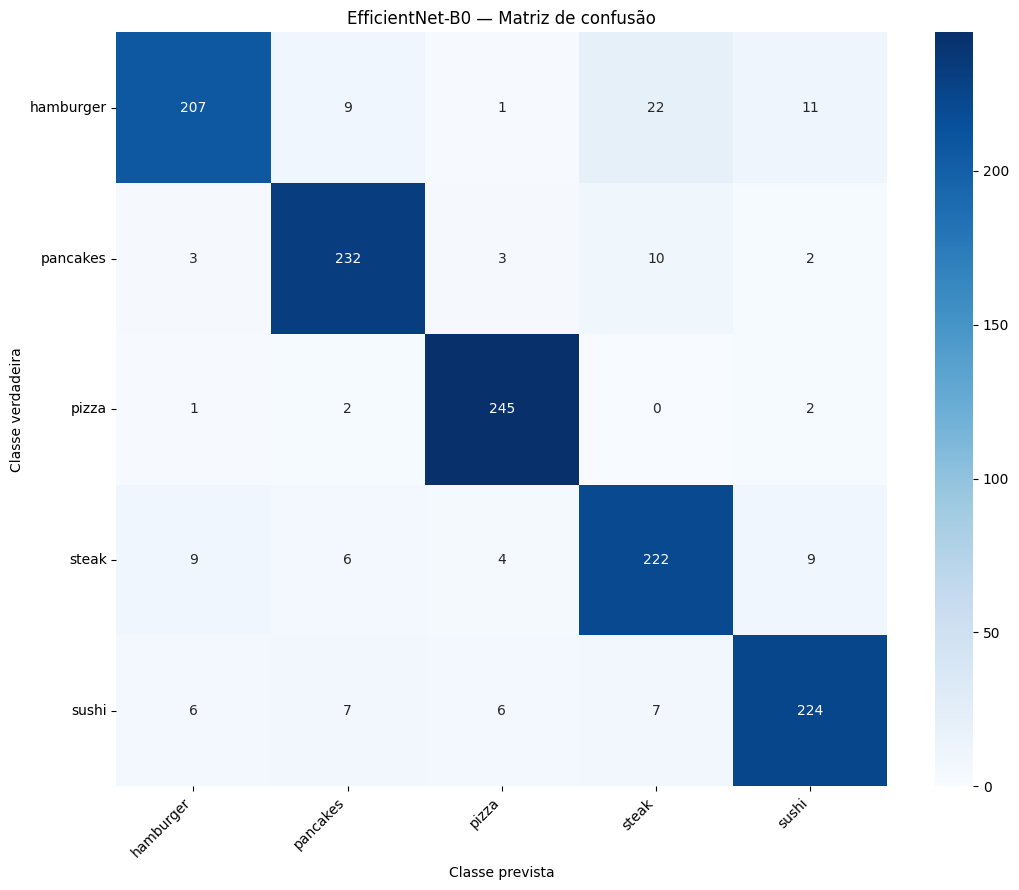

In [20]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("EfficientNet-B0 — Matriz de confusão")
plt.xlabel("Classe prevista")
plt.ylabel("Classe verdadeira")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=180
)

plt.show()

In [21]:
model = model.cpu()
model.eval()

checkpoint = {
    "model_name": "efficientnet_b0",
    "num_classes": len(class_names),
    "class_names": class_names,
    "state_dict": model.state_dict(),
    "image_size": 224,
    "mean": [0.485, 0.456, 0.406],
    "std": [0.229, 0.224, 0.225],
    "best_epoch": best_epoch,
    "metrics": metrics,
}

checkpoint_path = (
    OUTPUT_DIR / "efficientnet_b0_food10.pth"
)

torch.save(checkpoint, checkpoint_path)

with open(
    OUTPUT_DIR / "classes.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(class_names, f, indent=2, ensure_ascii=False)

print("Modelo guardado em:", checkpoint_path)
print("Conteúdo da pasta:", os.listdir(OUTPUT_DIR))

Modelo guardado em: /content/foodvision_efficientnet/efficientnet_b0_food10.pth
Conteúdo da pasta: ['efficientnet_b0_food10.pth', 'classes.json', 'metrics.json', 'training_curves.png', 'metrics.csv', 'training_history.csv', 'confusion_matrix.png']
